In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import cmcrameri.cm as cm
from scipy.stats import linregress

In [3]:
matplotlib.rcParams['mathtext.fontset'] = 'cm'
matplotlib.rcParams['font.family'] = 'STIXGeneral'

def set_size(width, fraction=1, subplots=(1, 1)):
    """
    Set figure dimensions to avoid scaling in LaTeX.
    This code is from: https://jwalton.info/Embed-Publication-Matplotlib-Latex/

    Parameters
    ----------
    width: float or string
            Document width in points, or string of predined document type
    fraction: float, optional
            Fraction of the width which you wish the figure to occupy
    subplots: array-like, optional
            The number of rows and columns of subplots.
    Returns
    -------
    fig_dim: tuple
            Dimensions of figure in inches
    """
    if width == 'thesis':
        width_pt = 426.79135
        width_pt = width_pt / 72.27
    elif width == 'beamer':
        width_pt = 307.28987
        width_pt = width_pt / 72.27
    else:
        width_pt = width

    # Golden ratio to set aesthetic figure height
    # https://disq.us/p/2940ij3
    golden_ratio = (5**.5 - 1) / 2


    fig_width_in = width_pt * fraction
    fig_height_in = fig_width_in * golden_ratio * (subplots[0] / subplots[1])

    return (fig_width_in, fig_height_in)


fig_width, fig_height = set_size('thesis')

import os

os.chdir('/data/rja92/HCN-Delivery-Paper')
cwd = os.getcwd()
print(cwd)

/data/rja92/HCN-Delivery-Paper


In [4]:
def compute_slope_in_range(R, N, r_min, r_max):


    mask = (R >= r_min) & (R <= r_max)

    log_R = np.log10(R[mask])
    log_N = np.log10(N[mask])
    

    slope, intercept = np.polyfit(log_R, log_N, 1)
    return slope, intercept

In [5]:
data = np.loadtxt(cwd +"/data/size_distribution.dat", comments="#")

In [6]:
R = data[:, 1]
N_R = data[:, 2]

Verifying the differential SFD has correct slope in each size range:
1.24999992188432
2.000636702739792
4.999999819731084
-1.2499999218843185 -1.999634790525947 -4.999998867397605


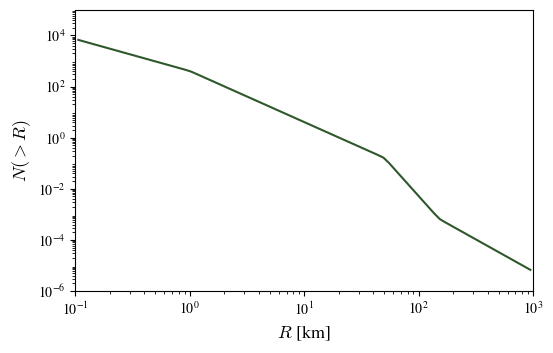

In [7]:
_ = plt.figure(figsize=set_size('thesis'))

plt.plot(R, N_R, c=cm.bamako(0.3))

ranges = [(0.1, 1), (1, 50), (50, 100)]
counter = 0
heights = [30, 0.2, 0.01]
print("Verifying the differential SFD has correct slope in each size range:")
for r_min, r_max in ranges:
    slope, intercept = compute_slope_in_range(R, N_R, r_min, r_max)
    print(np.abs(slope))
    counter += 1

i_subkm = R < 1
subkm_slope = linregress(np.log10(R[i_subkm]), np.log10(N_R[i_subkm])).slope
i_large = np.logical_and(R >= 50, R <= 150)
large_slope = linregress(np.log10(R[i_large]), np.log10(N_R[i_large])).slope
i_km = np.logical_and(R >= 1, R <= 10)
km_slope = linregress(np.log10(R[i_km]), np.log10(N_R[i_km])).slope
print(subkm_slope, km_slope, large_slope)

plt.xlabel(r'$R$ [km]', fontsize=13)
plt.ylabel(r'$N(>R)$', fontsize=13)

plt.xscale('log')
plt.yscale('log')

plt.xlim(1e-1, 1e3)
plt.ylim(1e-6, 1e5)

plt.gca().yaxis.set_major_locator(matplotlib.ticker.LogLocator(numticks=6))
plt.gca().yaxis.set_minor_locator(matplotlib.ticker.LogLocator(numticks=999, subs="auto"))

# plt.savefig(cwd + '/figures/JFC_SFD.pdf', format='pdf', bbox_inches='tight')

plt.show()

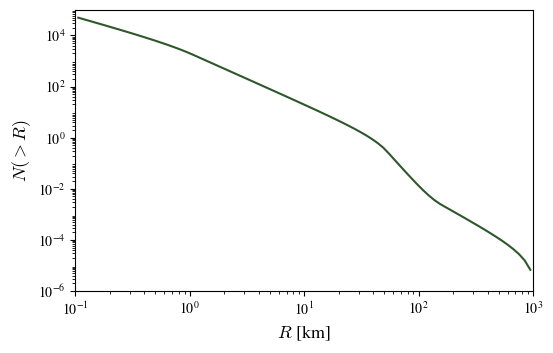

In [8]:
_ = plt.figure(figsize=set_size('thesis'))

N_R_CSD = np.cumsum(N_R[::-1])[::-1]
plt.plot(R, N_R_CSD, c=cm.bamako(0.3))

plt.xlabel(r'$R$ [km]', fontsize=13)
plt.ylabel(r'$N(>R)$', fontsize=13)

plt.xscale('log')
plt.yscale('log')

plt.xlim(1e-1, 1e3)
plt.ylim(1e-6, 1e5)

plt.gca().yaxis.set_major_locator(matplotlib.ticker.LogLocator(numticks=6))
plt.gca().yaxis.set_minor_locator(matplotlib.ticker.LogLocator(numticks=999, subs="auto"))

# plt.savefig(cwd + '/figures/JFC_SFD.pdf', format='pdf', bbox_inches='tight')

plt.show()

### Here we generate finite numbers per bin drawing from poisson distribution with mean as above...

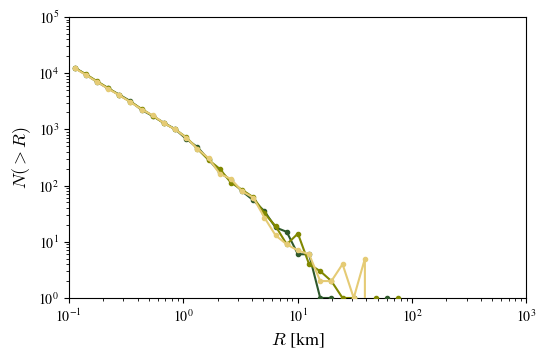

In [37]:
_ = plt.figure(figsize=set_size('thesis'))

for i in [1, 2, 3]:
    fpath = cwd +"/data/finite_example/gen_size_dist" + str(i) + ".dat"
    data = np.loadtxt(fpath, comments="#")
    R = data[:, 1]
    N_R = data[:, 2]

    plt.plot(R, N_R, c=cm.bamako(0.3 * int(i)), zorder=10, marker='.')

plt.xlabel(r'$R$ [km]', fontsize=13)
plt.ylabel(r'$N(>R)$', fontsize=13)

plt.xscale('log')
plt.yscale('log')

plt.xlim(1e-1, 1e3)
plt.ylim(1e0, 1e5)

plt.gca().yaxis.set_major_locator(matplotlib.ticker.LogLocator(numticks=6))
plt.gca().yaxis.set_minor_locator(matplotlib.ticker.LogLocator(numticks=999, subs="auto"))

# plt.savefig(cwd + '/figures/JFC_SFD.pdf', format='pdf', bbox_inches='tight')

plt.show()

In [9]:
data = np.loadtxt(cwd +"/data/size_distribution.dat", comments="#")

nfiles = 100000
all_N_R = []

for i in range(1, nfiles + 1):
    print(round(100 * i / nfiles, 2), end='%\r')
    fname = cwd + "/data/nrt_disisto_12e3/nrt_" + str(i) + ".dat"
    dout = np.loadtxt(fname, comments="#")
    N_R = dout[:, 2]
    all_N_R.append(N_R)

all_N_R = np.array(all_N_R)
avg_N_R_DS = np.mean(all_N_R, axis=0)

data = np.loadtxt(cwd +"/data/size_distribution.dat", comments="#")

nfiles = 100000
all_N_R = []

for i in range(1, nfiles + 1):
    print(round(100 * i / nfiles, 2), end='%\r')
    fname = cwd + "/data/nrt_jewitt_12e3/nrt_" + str(i) + ".dat"
    dout = np.loadtxt(fname, comments="#")
    N_R = dout[:, 2]
    all_N_R.append(N_R)

all_N_R = np.array(all_N_R)
avg_N_R_J = np.mean(all_N_R, axis=0)

81 81
111 0.7836945483296496
111 1.3366164345764575
111 4.736375137339094
-0.7836945483296489 -1.3366164345764564 -4.736375137339097
222 0.779117488411598
222 1.3393053700295232
222 4.776116756778497
-0.7791174884115979 -1.3393053700295228 -4.776116756778503


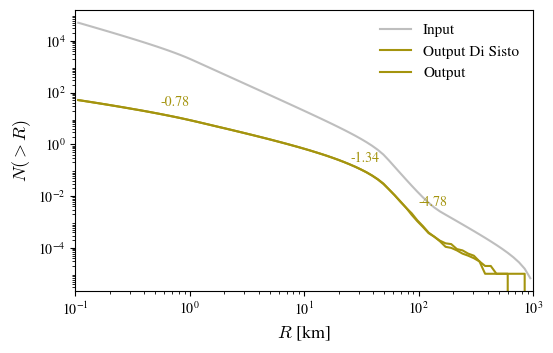

In [ ]:
R = data[:, 1]
N_R = data[:, 2]
print(len(R), len(N_R))

ranges = [(0.1, 1), (1, 50), (50, 150)]

_ = plt.figure(figsize=set_size('thesis'))

plt.plot(R, np.cumsum(N_R[::-1])[::-1], c='tab:gray', label='Input', alpha=0.5)

avg_cum = np.cumsum(avg_N_R_DS[::-1])[::-1]

counter = 0
heights = [30, 0.2, 0.004]
for r_min, r_max in ranges:
    slope, intercept = compute_slope_in_range(R, avg_cum, r_min, r_max)
    print(111, np.abs(slope))
    counter += 1

i_subkm = R < 1
subkm_slope = linregress(np.log10(R[i_subkm]), np.log10(avg_cum[i_subkm])).slope
i_large = np.logical_and(R >= 50, R <= 150)
large_slope = linregress(np.log10(R[i_large]), np.log10(avg_cum[i_large])).slope
i_km = np.logical_and(R >= 1, R <= 50)
km_slope = linregress(np.log10(R[i_km]), np.log10(avg_cum[i_km])).slope
print(subkm_slope, km_slope, large_slope)

avg_cum = np.cumsum(avg_N_R_J[::-1])[::-1]
plt.plot(R, avg_cum, c=cm.bamako(0.7), label='Output')

counter = 0
heights = [30, 0.2, 0.004]
for r_min, r_max in ranges:
    slope, intercept = compute_slope_in_range(R, avg_cum, r_min, r_max)
    plt.text(0.5 * (r_min + r_max), heights[counter], round(slope, 2), color=cm.bamako(0.7))
    print(222, np.abs(slope))
    counter += 1

i_subkm = R < 1
subkm_slope = linregress(np.log10(R[i_subkm]), np.log10(avg_cum[i_subkm])).slope
i_large = np.logical_and(R >= 50, R <= 150)
large_slope = linregress(np.log10(R[i_large]), np.log10(avg_cum[i_large])).slope
i_km = np.logical_and(R >= 1, R <= 50)
km_slope = linregress(np.log10(R[i_km]), np.log10(avg_cum[i_km])).slope
print(subkm_slope, km_slope, large_slope)

plt.xlabel(r'$R$ [km]', fontsize=13)
plt.ylabel(r'$N(>R)$', fontsize=13)

plt.xscale('log')
plt.yscale('log')

plt.xlim(1e-1, 1e3)
plt.ylim(1e-5, 1e5)

plt.gca().yaxis.set_major_locator(matplotlib.ticker.LogLocator(numticks=6))
plt.gca().yaxis.set_minor_locator(matplotlib.ticker.LogLocator(numticks=999, subs="auto"))

plt.legend(frameon=False, fontsize=11)

# plt.savefig(cwd + '/figures/SFD_evol.pdf', format='pdf', bbox_inches='tight')

plt.show()

### verifying the mass in each bin reaches steady state

In [317]:
data = np.loadtxt(cwd +"/data/size_distribution.dat", comments="#")

nfiles = 100000

times = np.arange(0, nfiles * 100, 100)

N_R0, N_R1, N_R10, N_R40 = [], [], [], []
for i in range(1, nfiles + 1):
    fname = cwd + "/data/nrt_disisto_12e5/nrt_" + str(i) + ".dat"
    dout = np.loadtxt(fname, comments="#")
    N_R = dout[:, 2]
    N_R0.append(N_R[0])
    N_R1.append(N_R[1])
    N_R10.append(N_R[10])
    N_R40.append(N_R[30])

N_R0 = np.array(N_R0)
N_R1 = np.array(N_R1)
N_R10 = np.array(N_R10)
N_R40 = np.array(N_R40)

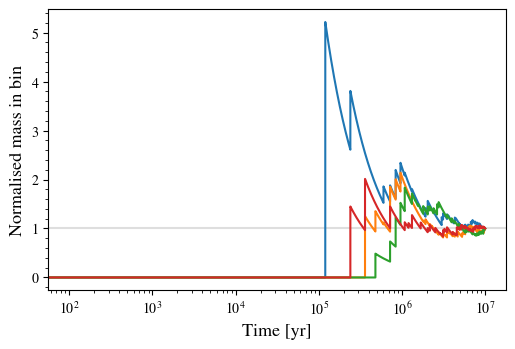

In [318]:
cum_avg0 = np.cumsum(N_R0) / (np.arange(1, len(N_R0) + 1))
cum_avg1 = np.cumsum(N_R1) / (np.arange(1, len(N_R1) + 1))
cum_avg10 = np.cumsum(N_R10) / (np.arange(1, len(N_R10) + 1))
cum_avg40 = np.cumsum(N_R40) / (np.arange(1, len(N_R40) + 1))

_ = plt.figure(figsize=set_size('thesis'))

plt.plot(times, cum_avg0 / cum_avg0[-1])
plt.plot(times, cum_avg1 / cum_avg1[-1])
plt.plot(times, cum_avg10 / cum_avg10[-1])
plt.plot(times, cum_avg40 / cum_avg40[-1])

plt.axhline(1, c='tab:gray', alpha=0.25, zorder=0)

plt.xscale('log')

plt.xlabel(r'Time [yr]', fontsize=13)
plt.ylabel(r'Normalised mass in bin', fontsize=13)

plt.minorticks_on()

In [324]:
data = np.loadtxt(cwd +"/data/size_distribution.dat", comments="#")

nfiles = 100000

times = np.arange(0, nfiles * 100, 100)

N_R0, N_R1, N_R10, N_R40 = [], [], [], []
for i in range(1, nfiles + 1):
    fname = cwd + "/data/nrt_jewitt_12e4/nrt_" + str(i) + ".dat"
    dout = np.loadtxt(fname, comments="#")
    N_R = dout[:, 2]
    N_R0.append(N_R[0])
    N_R1.append(N_R[1])
    N_R10.append(N_R[10])
    N_R40.append(N_R[30])

N_R0 = np.array(N_R0)
N_R1 = np.array(N_R1)
N_R10 = np.array(N_R10)
N_R40 = np.array(N_R40)

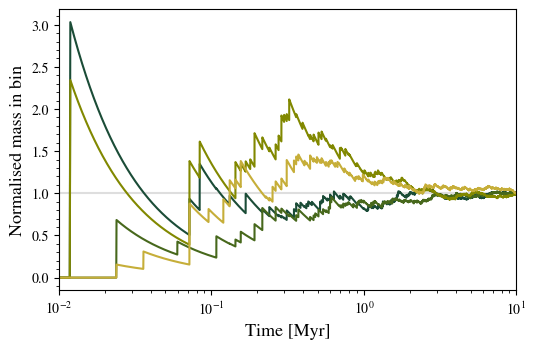

In [ ]:
cum_avg0 = np.cumsum(N_R0) / (np.arange(1, len(N_R0) + 1))
cum_avg1 = np.cumsum(N_R1) / (np.arange(1, len(N_R1) + 1))
cum_avg10 = np.cumsum(N_R10) / (np.arange(1, len(N_R10) + 1))
cum_avg40 = np.cumsum(N_R40) / (np.arange(1, len(N_R40) + 1))

_ = plt.figure(figsize=set_size('thesis'))

plt.plot(times / 1e6, cum_avg0 / cum_avg0[-1], c=cm.bamako(0.2))
plt.plot(times / 1e6, cum_avg1 / cum_avg1[-1], c=cm.bamako(0.4))
plt.plot(times / 1e6, cum_avg10 / cum_avg10[-1], c=cm.bamako(0.6))
plt.plot(times / 1e6, cum_avg40 / cum_avg40[-1], c=cm.bamako(0.8))

plt.axhline(1, c='tab:gray', alpha=0.25, zorder=0)

plt.xscale('log')
plt.xlim(1e-2, 1e1)

plt.xlabel(r'Time [Myr]', fontsize=13)
plt.ylabel(r'Normalised mass in bin', fontsize=13)

plt.minorticks_on()

# plt.savefig(cwd + '/figures/jewitt_SFD_convergence.pdf', format='pdf', bbox_inches='tight')

plt.show()

### comparing slopes with varying comet lifetime (i.e. 12000yr)

In [332]:
import re

def read_slope(fpath):

    with open(fpath, 'r') as f:
        lines = f.readlines()

    slope_vals = []
    for line in lines:
        match = re.search(r"Slope \(abs\): ([\d.]+)", line)
        if match:
            slope = float(match.group(1))
            slope_vals.append(slope)

    return np.array(slope_vals)

In [345]:
slopesDS3 = read_slope(cwd +"/data/output_slopes_DS3.dat")
slopesDS4 = read_slope(cwd +"/data/output_slopes_DS4.dat")
slopesDS5 = read_slope(cwd +"/data/output_slopes_DS5.dat") 

slopesJ3 = read_slope(cwd +"/data/output_slopes_J3.dat")
slopesJ4 = read_slope(cwd +"/data/output_slopes_J4.dat")
slopesJ5 = read_slope(cwd +"/data/output_slopes_J5.dat") 

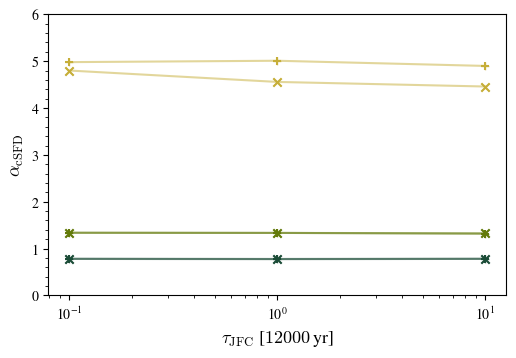

In [ ]:
delta_ts = [0.1, 1, 10]

_ = plt.figure(figsize=set_size('thesis'))

plt.plot(delta_ts, [slopesDS3[0], slopesDS4[0], slopesDS5[0]], marker='x', alpha=0.5, color=cm.bamako(0.2))
plt.plot(delta_ts, [slopesDS3[1], slopesDS4[1], slopesDS5[1]], marker='x', alpha=0.5, color=cm.bamako(0.5))
plt.plot(delta_ts, [slopesDS3[2], slopesDS4[2], slopesDS5[2]], marker='x', alpha=0.5, color=cm.bamako(0.8))

plt.scatter(delta_ts, [slopesDS3[0], slopesDS4[0], slopesDS5[0]], marker='x', color=cm.bamako(0.2))
plt.scatter(delta_ts, [slopesDS3[1], slopesDS4[1], slopesDS5[1]], marker='x', color=cm.bamako(0.5))
plt.scatter(delta_ts, [slopesDS3[2], slopesDS4[2], slopesDS5[2]], marker='x', color=cm.bamako(0.8))

plt.plot(delta_ts, [slopesJ3[0], slopesJ4[0], slopesJ5[0]], marker='+', alpha=0.5, color=cm.bamako(0.2))
plt.plot(delta_ts, [slopesJ3[1], slopesJ4[1], slopesJ5[1]], marker='+', alpha=0.5, color=cm.bamako(0.5))
plt.plot(delta_ts, [slopesJ3[2], slopesJ4[2], slopesJ5[2]], marker='+', alpha=0.5, color=cm.bamako(0.8))

plt.scatter(delta_ts, [slopesJ3[0], slopesJ4[0], slopesJ5[0]], marker='+', color=cm.bamako(0.2))
plt.scatter(delta_ts, [slopesJ3[1], slopesJ4[1], slopesJ5[1]], marker='+', color=cm.bamako(0.5))
plt.scatter(delta_ts, [slopesJ3[2], slopesJ4[2], slopesJ5[2]], marker='+', color=cm.bamako(0.8))

plt.xscale('log')

plt.xlabel(r'$\tau_{\rm JFC}$ [$12000\,$yr]', fontsize=13)
plt.ylabel(r'$\alpha_{\rm cSFD}$', fontsize=13)

plt.ylim(0, 6)

plt.minorticks_on()

# plt.savefig(cwd + '/figures/tau_JFC.pdf', format='pdf', bbox_inches='tight')

plt.show()

### comparing slopes with varying timesteps

changing delta_t should not change the shape of the SFD.

In [378]:
slopesDS_dt01 = read_slope(cwd +"/data/output_slopes_DS4.dat")
slopesDS_dt1 = read_slope(cwd +"/data/output_slopes_DS_dt1.dat")
slopesDS_dt10 = read_slope(cwd +"/data/output_slopes_DS_dt10.dat")

slopesJ_dt01 = read_slope(cwd +"/data/output_slopes_J4.dat")
slopesJ_dt1 = read_slope(cwd +"/data/output_slopes_J_dt1.dat")
slopesJ_dt10 = read_slope(cwd +"/data/output_slopes_J_dt10.dat") 

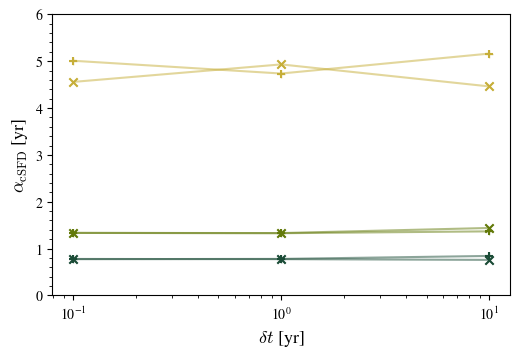

In [ ]:
delta_ts = [0.1, 1, 10]

_ = plt.figure(figsize=set_size('thesis'))

plt.plot(delta_ts, [slopesDS_dt01[0], slopesDS_dt1[0], slopesDS_dt10[0]], marker='x', alpha=0.5, color=cm.bamako(0.2))
plt.plot(delta_ts, [slopesDS_dt01[1], slopesDS_dt1[1], slopesDS_dt10[1]], marker='x', alpha=0.5, color=cm.bamako(0.5))
plt.plot(delta_ts, [slopesDS_dt01[2], slopesDS_dt1[2], slopesDS_dt10[2]], marker='x', alpha=0.5, color=cm.bamako(0.8))

plt.scatter(delta_ts, [slopesDS_dt01[0], slopesDS_dt1[0], slopesDS_dt10[0]], marker='x', color=cm.bamako(0.2))
plt.scatter(delta_ts, [slopesDS_dt01[1], slopesDS_dt1[1], slopesDS_dt10[1]], marker='x', color=cm.bamako(0.5))
plt.scatter(delta_ts, [slopesDS_dt01[2], slopesDS_dt1[2], slopesDS_dt10[2]], marker='x', color=cm.bamako(0.8))

plt.plot(delta_ts, [slopesJ_dt01[0], slopesJ_dt1[0], slopesJ_dt10[0]], marker='+', alpha=0.5, color=cm.bamako(0.2))
plt.plot(delta_ts, [slopesJ_dt01[1], slopesJ_dt1[1], slopesJ_dt10[1]], marker='+', alpha=0.5, color=cm.bamako(0.5))
plt.plot(delta_ts, [slopesJ_dt01[2], slopesJ_dt1[2], slopesJ_dt10[2]], marker='+', alpha=0.5, color=cm.bamako(0.8))

plt.scatter(delta_ts, [slopesJ_dt01[0], slopesJ_dt1[0], slopesJ_dt10[0]], marker='+', color=cm.bamako(0.2))
plt.scatter(delta_ts, [slopesJ_dt01[1], slopesJ_dt1[1], slopesJ_dt10[1]], marker='+', color=cm.bamako(0.5))
plt.scatter(delta_ts, [slopesJ_dt01[2], slopesJ_dt1[2], slopesJ_dt10[2]], marker='+', color=cm.bamako(0.8))

plt.xscale('log')

plt.xlabel(r'$\delta t$ [yr]', fontsize=13)
plt.ylabel(r'$\alpha_{\rm cSFD}$ [yr]', fontsize=13)

plt.ylim(0, 6)

plt.minorticks_on()

# plt.savefig(cwd + '/figures/delta_t.pdf', format='pdf', bbox_inches='tight')

plt.show()

In [365]:
out1 = read_slope(cwd +"/data/output_slopes_DS4.dat")
out1

array([0.778447, 1.333824, 4.558034])